# Bước 2.3 — Gom cụm kỹ năng (K-Means)

**Câu hỏi:** các tin tuyển dụng IT có thể chia thành những nhóm kỹ năng nào, và mỗi nhóm trông như thế nào?

**Đầu vào:** `clean_data_processed.csv` (từ bước 2.1) — mỗi tin có danh sách `skills`.
**Đầu ra:** các cụm đã đặt tên, bảng chân dung cụm và file `data/cluster_assignments.csv` cho bước 2.4, 2.5.

| Phần | Nội dung |
| ---- | -------- |
| 2.3.0 | Cấu hình, đọc dữ liệu, hàm dùng chung |
| 2.3.1 | Chuẩn bị đầu vào (1): `NaN` trong cột văn bản |
| 2.3.2 | Chuẩn bị đầu vào (2): tin có vector kỹ năng toàn 0 |
| 2.3.3 | Chọn đặc trưng, mẫu số và chuẩn hóa vector |
| 2.3.4 | Chọn K: Elbow, Silhouette và độ ổn định |
| 2.3.5 | Gom cụm và lập hồ sơ cụm |
| 2.3.6 | Đặt tên cụm |
| 2.3.7 | Kiểm tra độ tin cậy của cụm |
| 2.3.8 | Hình 2D (PCA) |
| 2.3.9 | Tổng kết mẫu số và lưu kết quả |

**Thuật ngữ dùng trong notebook**

| Thuật ngữ | Nghĩa ngắn gọn |
| --------- | -------------- |
| Vector kỹ năng | Mỗi tin là một dòng 0/1: tin có (1) hay không có (0) từng kỹ năng |
| K-Means | Chia các tin thành K nhóm sao cho tin cùng nhóm gần nhau |
| Inertia | Tổng bình phương khoảng cách từ tin tới tâm cụm. Càng nhỏ càng gọn, nhưng luôn giảm khi tăng K |
| Silhouette | Từ −1 đến 1. Càng cao thì tin càng gần cụm của mình và càng xa các cụm khác |
| ARI | Độ giống nhau của hai lần gom cụm (1 = giống hệt, 0 = ngẫu nhiên) |
| Lift của kỹ năng | Tỷ lệ kỹ năng trong cụm ÷ tỷ lệ trong toàn mẫu. Lớn hơn 1 nghĩa là cụm này nhắc kỹ năng đó nhiều hơn bình thường |

## 2.3.0 — Cấu hình, đọc dữ liệu, hàm dùng chung

Mọi tham số của bước này nằm trong **một ô duy nhất** bên dưới. Muốn thử ngưỡng khác chỉ cần sửa ở đây rồi chạy lại.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.preprocessing import MultiLabelBinarizer, normalize

# ---- Đường dẫn ----
DATA_PATH = Path("../buoc2.1_2.2/data/processed/clean_data_processed.csv")
OUTPUT_PATH = Path("data/cluster_assignments.csv")

# ---- Tham số gom cụm ----
RANDOM_STATE = 42             # dùng chung mọi nơi để chạy lại ra cùng kết quả
MIN_SKILLS_PER_JOB = 3        # tin phải có ít nhất 3 kỹ năng mới được gom cụm
MIN_JOBS_PER_SKILL = 10       # kỹ năng phải có ở ít nhất 10 tin mới được dùng
K_RANGE = range(2, 13)        # các giá trị K đem so sánh
STABILITY_SEEDS = [1, 2, 3, 4, 5]  # 5 lần chạy lại với hạt giống khác để đo độ ổn định
MIN_CLUSTER_SHARE = 0.05      # quy tắc chọn K: mỗi cụm có ít nhất 5% số tin
MIN_STABILITY_ARI = 0.80      # quy tắc chọn K: ARI trung bình giữa các lần chạy >= 0,80
PROFILE_MIN_SHARE = 0.25      # kỹ năng "đặc trưng" phải có ở >= 25% tin trong cụm

# ---- Màu biểu đồ: một màu chính, xám cho phần nền ----
INK, MUTED, GRID, BLUE, GRAY = "#0b0b0b", "#898781", "#e1e0d9", "#2a78d6", "#c3c2b7"

plt.rcParams.update(
    {
        "figure.dpi": 100,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": GRAY,
        "axes.labelcolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "lines.linewidth": 2,
    }
)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

In [2]:
df_all = pd.read_csv(DATA_PATH)

# Chỉ khôi phục danh sách kỹ năng, giống cách làm ở 2.2
df_all["skills"] = df_all["skills"].map(json.loads)

df = df_all.loc[df_all["scope_status"].eq("included_provisional")].copy()

print(f"Tổng tin đại diện: {len(df_all):,}")
print(f"Tin IT dùng sơ bộ: {len(df):,}")

Tổng tin đại diện: 3,135
Tin IT dùng sơ bộ: 2,869


**Hàm dùng chung.** Gom vào một ô để các mục sau chỉ việc gọi, không lặp lại code.

| Hàm | Việc làm |
| --- | -------- |
| `build_matrix` | Lọc kỹ năng hiếm và tin ít kỹ năng, trả về ma trận 0/1 |
| `evaluate_k` | Với mỗi K: tính inertia, Silhouette, cụm nhỏ nhất và độ ổn định (ARI) |
| `describe_clusters` | Tính kích thước, kỹ năng đặc trưng (lift) và kỹ năng phổ biến của từng cụm |
| `name_clusters` | Gán tên cụm bằng cách so kỹ năng đặc trưng với "chữ ký" của từng tên |

In [3]:
def build_matrix(frame, min_jobs_per_skill, min_skills_per_job):
    """Lọc kỹ năng hiếm và tin ít kỹ năng, trả về (bảng tin, ma trận 0/1, tên kỹ năng).

    Bỏ tin có thể làm một kỹ năng tụt dưới ngưỡng, và ngược lại, nên lặp cho đến khi
    cả hai ngưỡng cùng đúng.
    """
    out = frame.copy()
    out["skills_model"] = out["skills"]

    while True:
        counts = pd.Series([s for xs in out["skills_model"] for s in xs]).value_counts()
        common = set(counts[counts >= min_jobs_per_skill].index)

        trimmed = out["skills_model"].map(lambda xs: [s for s in xs if s in common])
        enough = trimmed.map(len) >= min_skills_per_job
        unchanged = enough.all() and trimmed.map(len).eq(out["skills_model"].map(len)).all()

        out["skills_model"] = trimmed
        out = out.loc[enough].copy()
        if unchanged:
            break

    out = out.reset_index(drop=True)
    mlb = MultiLabelBinarizer()
    X = mlb.fit_transform(out["skills_model"])
    return out, X, np.array(mlb.classes_)


def evaluate_k(X_norm, k_values, seeds=STABILITY_SEEDS):
    """Với mỗi K, chạy K-Means chuẩn rồi chạy lại với các hạt giống khác để đo độ ổn định."""
    rows = []
    for k in k_values:
        ref = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_norm)
        other_runs = [
            KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(X_norm) for seed in seeds
        ]
        rows.append(
            {
                "k": k,
                "inertia": ref.inertia_,
                "silhouette": silhouette_score(X_norm, ref.labels_),
                "min_cluster_pct": np.bincount(ref.labels_).min() / len(X_norm) * 100,
                "mean_ari": np.mean([adjusted_rand_score(ref.labels_, run) for run in other_runs]),
            }
        )
    return pd.DataFrame(rows).set_index("k")


def describe_clusters(X, labels, skill_names, min_share=PROFILE_MIN_SHARE, top_n=8):
    """Mô tả từng cụm: kích thước, kỹ năng đặc trưng (lift cao) và kỹ năng phổ biến nhất."""
    overall = X.mean(axis=0)  # tỷ lệ mỗi kỹ năng trong toàn mẫu
    rows = []
    for c in np.unique(labels):
        in_cluster = labels == c
        share = X[in_cluster].mean(axis=0)  # tỷ lệ mỗi kỹ năng trong cụm
        lift = share / overall

        # Chỉ xét kỹ năng có mặt đủ nhiều trong cụm, tránh kỹ năng hiếm có lift cao do may mắn
        eligible = share >= min_share
        distinctive = pd.Series(lift[eligible], index=skill_names[eligible]).nlargest(top_n)
        common = pd.Series(share, index=skill_names).nlargest(top_n)

        rows.append(
            {
                "cluster": c,
                "n_jobs": int(in_cluster.sum()),
                "pct": in_cluster.mean() * 100,
                "avg_skills": X[in_cluster].sum(axis=1).mean(),
                "top_lift": list(distinctive.index),
                "distinctive": ", ".join(f"{s} ({v:.1f}x)" for s, v in distinctive.items()),
                "common": ", ".join(f"{s} ({v * 100:.0f}%)" for s, v in common.head(5).items()),
            }
        )
    return pd.DataFrame(rows).set_index("cluster")


def name_clusters(top_lift_by_cluster, signatures, min_overlap=2):
    """Gán mỗi cụm tên có nhiều kỹ năng trùng nhất với kỹ năng đặc trưng của cụm."""
    names, overlaps = {}, {}
    for c, skills in top_lift_by_cluster.items():
        scores = {name: len(set(skills) & signature) for name, signature in signatures.items()}
        best = max(scores, key=scores.get)
        overlaps[c] = scores[best]
        names[c] = best if scores[best] >= min_overlap else f"Cụm {c} (chưa đặt tên)"
    return names, overlaps

## 2.3.1 — Chuẩn bị đầu vào (1): `NaN` trong cột văn bản

### Hiện tượng

Ở 2.1, tin không có JD có `description_clean = ""` và `text_for_tfidf = ""`. Sau khi lưu CSV rồi đọc lại, các ô này không còn là chuỗi rỗng.

In [4]:
text_columns = ["description_clean", "text_for_tfidf"]

print("Số ô NaN trong toàn bảng:")
display(df_all[text_columns].isna().sum().to_frame("so_nan"))

# Những dòng NaN là dòng nào?
nan_rows = df_all["text_for_tfidf"].isna()

display(
    pd.crosstab(
        [df_all.loc[nan_rows, "has_jd_clean"], df_all.loc[nan_rows, "scope_status"]],
        "so_tin",
    )
)

Số ô NaN trong toàn bảng:


,so_nan
description_clean,30
text_for_tfidf,30


col_0                              so_tin
has_jd_clean scope_status                
False        included_provisional      26
             pending_review             4

Cả 30 dòng đều là tin **không có JD** (`has_jd_clean = False`), trong đó 26 dòng thuộc tập IT dùng sơ bộ.

### Nguyên nhân

`to_csv` ghi chuỗi rỗng thành ô trống, còn `read_csv` mặc định đọc ô trống thành `NaN` (kiểu `float`). Ví dụ nhỏ:

In [5]:
import io

demo = pd.DataFrame({"text": ["python sql", ""]})

buffer = io.StringIO()
demo.to_csv(buffer, index=False)
buffer.seek(0)

demo_loaded = pd.read_csv(buffer)

print("Trước khi lưu:", demo["text"].tolist())
print("Sau khi đọc lại:", demo_loaded["text"].tolist())

Trước khi lưu: ['python sql', '']
Sau khi đọc lại: ['python sql', nan]


### Tái hiện lỗi

`TfidfVectorizer` yêu cầu mọi phần tử là chuỗi. Đưa thẳng cột vừa đọc vào sẽ lỗi:

In [6]:
try:
    TfidfVectorizer().fit_transform(df["text_for_tfidf"])
except Exception as error:
    print(f"{type(error).__name__}: {error}")

ValueError: np.nan is an invalid document, expected byte or unicode string.


### Sửa

Khôi phục `NaN` thành chuỗi rỗng cho **đúng hai cột văn bản**. Không áp dụng cho `languages` hay `benefits`: ở hai cột đó `NaN` nghĩa là chưa có dữ liệu, khác với danh sách rỗng, và 2.2.6 đã phân biệt hai trường hợp này.

Bước này cần chạy ngay sau khi đọc file, rồi mới tách `df`.

In [7]:
df_all[text_columns] = df_all[text_columns].fillna("")

df = df_all.loc[df_all["scope_status"].eq("included_provisional")].copy()

assert df_all[text_columns].notna().all().all()

### Kiểm tra lại

In [8]:
tfidf_demo = TfidfVectorizer(min_df=5).fit_transform(df["text_for_tfidf"])

print("TF-IDF chạy được. Kích thước ma trận:", tfidf_demo.shape)

# Các dòng rỗng vẫn được giữ, nhưng không có JD
n_empty_text = df["text_for_tfidf"].eq("").sum()

print("Tin có văn bản rỗng:", n_empty_text)

assert n_empty_text == (~df["has_jd_clean"]).sum()

TF-IDF chạy được. Kích thước ma trận: (2869, 8123)
Tin có văn bản rỗng: 26


> Nếu bước gom cụm luôn lọc `has_jd_clean` trước khi vector hóa thì 30 dòng này đã bị loại sẵn. `fillna("")` ở đây là biện pháp phòng thủ cho người chạy notebook mà quên lọc.

## 2.3.2 — Chuẩn bị đầu vào (2): tin có vector kỹ năng toàn 0

### Hiện tượng

Ma trận kỹ năng có 2.843 tin có JD. Một số tin có JD nhưng không trích được kỹ năng nào.

In [9]:
df_skills = df.loc[df["has_jd_clean"]].copy()

mlb = MultiLabelBinarizer()

X = mlb.fit_transform(df_skills["skills"])

is_zero = X.sum(axis=1) == 0

print("Kích thước ma trận:", X.shape)
print("Số tin có vector toàn 0:", is_zero.sum())
print(f"Tỷ lệ: {is_zero.mean() * 100:.1f}%")

assert is_zero.sum() == df_skills["n_skills"].eq(0).sum()

Kích thước ma trận: (2843, 157)
Số tin có vector toàn 0: 175
Tỷ lệ: 6.2%


In [10]:
# Những tin này có JD thật, chỉ là chưa trích được kỹ năng
zero_samples = df_skills.loc[is_zero].sample(5, random_state=42)

display(zero_samples[["source", "title", "jd_chars", "n_skills"]])

print("Một đoạn JD của tin đầu tiên:")
print(zero_samples.iloc[0]["description_clean"][:400])

,source,title,jd_chars,n_skills
2762,vietnamworks,Kỹ Sư FPGA,2055,0
2532,topdev,Mobile App Executive Officer,2305,0
2011,topcv,IT Helpdesk,1570,0
2334,topcv,[Fresher] Tư Vấn Thiết Kế Website_Được Đào Tạo,848,0
2518,topcv,Nhân Viên Phát Triển Phần Mềm &Kỹ Thuật Viễn Thông,3303,0


Một đoạn JD của tin đầu tiên:
Mô tả công việc - Thiết kế logic FPGA (Verilog/SystemVerilog/VHDL) cho: - Phát xung điều khiển qubit (DDS, IQ modulation, pulse shaping) - Thu nhận & xử lý tín hiệu readout (demodulation, filtering, averaging) - Triển khai xử lý tín hiệu và phản hồi thời gian thực (low-latency feedback) cho quantum control. - Làm việc với ADC/DAC tốc độ cao, clock chính xác, đồng bộ đa miền clock. - Tích hợp FPGA 


In [11]:
display(
    df_skills.loc[is_zero, "source"]
    .value_counts()
    .to_frame("so_tin_0_ky_nang")
    .join(df_skills["source"].value_counts().rename("tong_tin_co_jd"))
    .assign(ty_le_pct=lambda t: (t["so_tin_0_ky_nang"] / t["tong_tin_co_jd"] * 100).round(1))
)

,so_tin_0_ky_nang,tong_tin_co_jd,ty_le_pct
source,,,
topcv,119,1138,10.5
vietnamworks,27,477,5.7
itviec,14,530,2.6
linkedin,10,637,1.6
topdev,5,61,8.2


### Tái hiện

Chạy KMeans trên toàn bộ 2.843 tin, **không loại** các vector toàn 0, rồi xem 175 tin đó rơi vào cụm nào.

In [12]:
K_DEMO = 8  # chỉ để minh họa lỗi; K thật được chọn ở 2.3.4

km_all = KMeans(n_clusters=K_DEMO, n_init=10, random_state=42).fit(X)

labels = km_all.labels_

cluster_table = pd.DataFrame(
    {
        "n_tin": pd.Series(labels).value_counts().sort_index(),
        "n_vector_0": pd.Series(labels[is_zero]).value_counts(),
        "so_ky_nang_tb": pd.Series(X.sum(axis=1)).groupby(labels).mean(),
    }
).fillna(0)

cluster_table["n_vector_0"] = cluster_table["n_vector_0"].astype(int)
cluster_table["vector_0_pct"] = cluster_table["n_vector_0"] / cluster_table["n_tin"] * 100

display(cluster_table.round(2))

absorbing_cluster = cluster_table["n_vector_0"].idxmax()

print(f"Cụm {absorbing_cluster} chứa {cluster_table.loc[absorbing_cluster, 'n_vector_0']} / {is_zero.sum()} tin vector 0")

,n_tin,n_vector_0,so_ky_nang_tb,vector_0_pct
0,505,0,6.02,0.00
1,237,0,11.91,0.00
2,910,175,2.79,19.23
3,397,0,6.40,0.00
4,245,0,16.54,0.00
5,188,0,15.78,0.00
6,178,0,12.32,0.00
7,183,0,5.91,0.00


Cụm 2 chứa 175 / 175 tin vector 0


Quan sát:

- Các tin vector 0 **không tự tạo thành một cụm riêng**. Chúng cùng rơi vào một cụm có sẵn (cụm lớn, ít kỹ năng) vì khoảng cách từ chúng tới tâm cụm nhỏ hơn tới tâm các cụm nhiều kỹ năng.
- Cụm đó trông "loãng" hơn thực tế: một phần thành viên không mang thông tin kỹ năng nào.

Xem ảnh hưởng lên tâm cụm đó:

In [13]:
in_cluster = labels == absorbing_cluster

centroid_with_zero = X[in_cluster].mean(axis=0)
centroid_without_zero = X[in_cluster & ~is_zero].mean(axis=0)

print("Tổng trọng số tâm cụm, có vector 0   :", centroid_with_zero.sum().round(2))
print("Tổng trọng số tâm cụm, bỏ vector 0   :", centroid_without_zero.sum().round(2))
print(
    "Tâm cụm bị kéo về gốc toạ độ khoảng",
    f"{(1 - centroid_with_zero.sum() / centroid_without_zero.sum()) * 100:.0f}%",
)

top_with = pd.Series(centroid_with_zero, index=mlb.classes_).nlargest(5)
top_without = pd.Series(centroid_without_zero, index=mlb.classes_).nlargest(5)

display(
    pd.DataFrame(
        {
            "top_ky_nang_co_vector_0": top_with.index,
            "ty_le_co_vector_0": top_with.round(3).to_numpy(),
            "top_ky_nang_bo_vector_0": top_without.index,
            "ty_le_bo_vector_0": top_without.round(3).to_numpy(),
        }
    )
)

Tổng trọng số tâm cụm, có vector 0   : 2.79
Tổng trọng số tâm cụm, bỏ vector 0   : 3.46
Tâm cụm bị kéo về gốc toạ độ khoảng 19%


,top_ky_nang_co_vector_0,ty_le_co_vector_0,top_ky_nang_bo_vector_0,ty_le_bo_vector_0
0,Agile,0.145,Agile,0.180
1,Scrum,0.116,Scrum,0.144
2,ERP,0.108,ERP,0.133
3,Jira,0.084,Jira,0.103
4,Android,0.082,Android,0.102


Tỷ lệ kỹ năng trong tâm cụm bị giảm đều, nên khi mô tả cụm ("cụm này thường có Python, SQL…") các con số bị thấp hơn thực tế.

> Chỉ nên đọc kết quả này như minh họa cơ chế. Không nên kết luận gì về độ lệch của cụm khác từ so sánh hai lần chạy KMeans, vì KMeans phụ thuộc khởi tạo ngẫu nhiên.

Quan trọng hơn là ý nghĩa: "không trích được kỹ năng" **không phải** một loại công việc. Gộp 175 tin này vào một cụm kỹ thuật sẽ làm bảng mô tả cụm sai.

### Sửa

Loại các vector toàn 0 khỏi đầu vào gom cụm, giữ riêng để báo cáo như nhóm "không trích được kỹ năng".

In [14]:
has_skill = df_skills["n_skills"].gt(0)

# Nhóm báo cáo riêng, không đưa vào gom cụm
df_no_skills = df_skills.loc[~has_skill].copy()

# Đầu vào gom cụm
df_cluster = df_skills.loc[has_skill].copy()

mlb_cluster = MultiLabelBinarizer()

X_cluster = mlb_cluster.fit_transform(df_cluster["skills"])

assert (X_cluster.sum(axis=1) > 0).all()
assert len(df_cluster) + len(df_no_skills) == len(df_skills)

print(f"Đầu vào gom cụm: {X_cluster.shape[0]:,} tin × {X_cluster.shape[1]} kỹ năng")
print(f"Nhóm không trích được kỹ năng: {len(df_no_skills):,} tin")

Đầu vào gom cụm: 2,668 tin × 157 kỹ năng
Nhóm không trích được kỹ năng: 175 tin


Lưu ý: bỏ các dòng có thể làm một kỹ năng không còn xuất hiện ở dòng nào, nên ma trận được dựng lại bằng `MultiLabelBinarizer` mới (số cột có thể giảm).

### Kiểm tra lại

In [15]:
km_clean = KMeans(n_clusters=K_DEMO, n_init=10, random_state=42).fit(X_cluster)

check = pd.DataFrame(
    {
        "n_tin": pd.Series(km_clean.labels_).value_counts().sort_index(),
        "so_ky_nang_tb": pd.Series(X_cluster.sum(axis=1)).groupby(km_clean.labels_).mean(),
    }
)

display(check.round(2))

print("Số vector 0 trong đầu vào gom cụm:", int((X_cluster.sum(axis=1) == 0).sum()))

,n_tin,so_ky_nang_tb
0,178,15.30
1,270,7.30
2,479,7.19
3,251,17.08
4,259,12.60
5,183,6.95
6,828,3.55
7,220,6.07


Số vector 0 trong đầu vào gom cụm: 0


## 2.3.3 — Chọn đặc trưng, mẫu số và chuẩn hóa vector

### Hai ngưỡng lọc

Ma trận kỹ năng rất thưa: trung vị mỗi tin chỉ có 6 kỹ năng trên 157 cột. Hai ngưỡng giúp khoảng cách giữa các tin có ý nghĩa hơn:

| Ngưỡng | Giá trị | Vì sao |
| ------ | ------: | ------ |
| Số kỹ năng tối thiểu mỗi tin | 3 | Tin chỉ có 1–2 kỹ năng gần như cách đều mọi tin khác, chỉ làm nhiễu |
| Số tin tối thiểu mỗi kỹ năng | 10 | Kỹ năng quá hiếm không đủ để tạo thành một nhóm |

Đặc trưng là cột `skills` của 2.1. `AI` và `Cloud` đã được tách sang `broad_concepts` ở 2.1 nên **không** nằm trong ma trận này.

In [16]:
# df_skills, df_cluster đã tạo ở 2.3.2 (tin có JD; tin có >= 1 kỹ năng)
df_model, X_model, skill_names = build_matrix(df_cluster, MIN_JOBS_PER_SKILL, MIN_SKILLS_PER_JOB)

n_no_skills = len(df_skills) - len(df_cluster)
n_few_skills = len(df_cluster) - len(df_model)

flow = pd.Series(
    {
        "Tin đại diện sau xử lý trùng (2.1)": len(df_all),
        "Tin IT dùng sơ bộ": len(df),
        "Tin có JD": len(df_skills),
        "  bỏ: không trích được kỹ năng nào": -n_no_skills,
        f"  bỏ: còn < {MIN_SKILLS_PER_JOB} kỹ năng sau khi bỏ kỹ năng hiếm": -n_few_skills,
        "Đầu vào gom cụm": len(df_model),
    },
    name="so_tin",
).to_frame()

display(flow)

assert len(df_model) == len(df_skills) - n_no_skills - n_few_skills
assert X_model.shape == (len(df_model), len(skill_names))
assert X_model.sum(axis=1).min() >= MIN_SKILLS_PER_JOB
assert X_model.sum(axis=0).min() >= MIN_JOBS_PER_SKILL

print(f"Ma trận gom cụm: {X_model.shape[0]:,} tin × {X_model.shape[1]} kỹ năng")

,so_tin
Tin đại diện sau xử lý trùng (2.1),3135
Tin IT dùng sơ bộ,2869
Tin có JD,2843
bỏ: không trích được kỹ năng nào,-175
bỏ: còn < 3 kỹ năng sau khi bỏ kỹ năng hiếm,-450
Đầu vào gom cụm,2218


Ma trận gom cụm: 2,218 tin × 143 kỹ năng


### Chuẩn hóa độ dài vector

Tin ghi 15 kỹ năng và tin ghi 6 kỹ năng khác nhau về **độ dài** vector, dù có thể cùng một hướng nghề. K-Means dùng khoảng cách Euclid nên dễ chia theo "tin ghi nhiều hay ít kỹ năng" thay vì "loại việc".

Cách xử lý: chia mỗi vector cho độ dài của nó (chuẩn hóa L2), chỉ còn lại *hướng*. Cách này tương đương dùng khoảng cách cosine.

Kiểm tra bằng số: với cùng K, xem cụm giải thích được bao nhiêu phần biến thiên của "số kỹ năng mỗi tin" (η², càng thấp càng tốt).

In [17]:
X_norm = normalize(X_model)  # mỗi dòng chia cho độ dài của nó
n_skills_per_job = X_model.sum(axis=1)


def share_explained_by_cluster(values, labels):
    """η²: phần biến thiên của `values` do việc chia cụm giải thích."""
    within = sum(((g - g.mean()) ** 2).sum() for _, g in pd.Series(values).groupby(labels))
    return 1 - within / ((values - values.mean()) ** 2).sum()


rows = []
for k in (4, 8, 12):
    raw_labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_model)
    norm_labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_norm)
    rows.append(
        {
            "K": k,
            "chưa chuẩn hóa": share_explained_by_cluster(n_skills_per_job, raw_labels),
            "đã chuẩn hóa": share_explained_by_cluster(n_skills_per_job, norm_labels),
        }
    )

display(pd.DataFrame(rows).set_index("K").round(2))

,chưa chuẩn hóa,đã chuẩn hóa
K,,
4,0.55,0.26
8,0.51,0.31
12,0.49,0.32


Sau chuẩn hóa, "số kỹ năng mỗi tin" ít quyết định cụm hơn. Phần còn lại là bình thường: nhóm DevOps hay Backend vốn ghi nhiều kỹ năng hơn nhóm mạng hay C/C++. Từ đây dùng `X_norm` cho mọi bước gom cụm.

## 2.3.4 — Chọn K: Elbow, Silhouette và độ ổn định

Với mỗi K từ 2 đến 12, ta tính:

- **Inertia** (Elbow): đường cong giảm dần, tìm "khuỷu" nơi độ giảm chậm lại.
- **Silhouette**: mức tách biệt giữa các cụm.
- **Cụm nhỏ nhất (%)**: tránh cụm quá nhỏ để mô tả.
- **ARI trung bình**: chạy lại với 5 hạt giống khác, so với lần chạy chuẩn. Gần 1 nghĩa là cụm không phụ thuộc may rủi.

In [18]:
k_table = evaluate_k(X_norm, K_RANGE)

k_table["inertia_drop_pct"] = -k_table["inertia"].pct_change() * 100
k_table["passes_rule"] = (k_table["min_cluster_pct"] >= MIN_CLUSTER_SHARE * 100) & (
    k_table["mean_ari"] >= MIN_STABILITY_ARI
)

display(
    k_table.rename(
        columns={
            "inertia": "inertia",
            "inertia_drop_pct": "giảm so với K−1 (%)",
            "silhouette": "silhouette",
            "min_cluster_pct": "cụm nhỏ nhất (%)",
            "mean_ari": "ARI trung bình",
            "passes_rule": "đạt quy tắc",
        }
    )[["inertia", "giảm so với K−1 (%)", "silhouette", "cụm nhỏ nhất (%)", "ARI trung bình", "đạt quy tắc"]].round(3)
)

,inertia,giảm so với K−1 (%),silhouette,cụm nhỏ nhất (%),ARI trung bình,đạt quy tắc
k,,,,,,
2,1828.705,NaN,0.044,39.991,0.964,True
3,1757.331,3.903,0.055,22.588,0.827,True
4,1696.691,3.451,0.056,21.190,0.693,False
5,1642.512,3.193,0.065,9.197,0.729,False
6,1591.399,3.112,0.070,9.558,0.844,True
7,1554.727,2.304,0.072,6.988,0.836,True
8,1521.415,2.143,0.074,6.718,0.860,True
9,1495.875,1.679,0.079,7.078,0.720,False
10,1468.688,1.817,0.078,4.779,0.783,False


### Quy tắc chọn K

Đặt ra **trước khi chọn**, để không chọn theo cảm tính:

1. Mỗi cụm có ít nhất **5%** số tin (không có cụm quá nhỏ).
2. ARI trung bình từ **0,80** trở lên (cụm ổn định).
3. Trong các K còn lại, chọn K có **Silhouette cao nhất**.

Elbow chỉ dùng để quan sát xu hướng.

K đạt quy tắc: [2, 3, 6, 7, 8]
Silhouette của các K đó: {2: 0.044, 3: 0.055, 6: 0.07, 7: 0.072, 8: 0.074}
K được chọn: 8


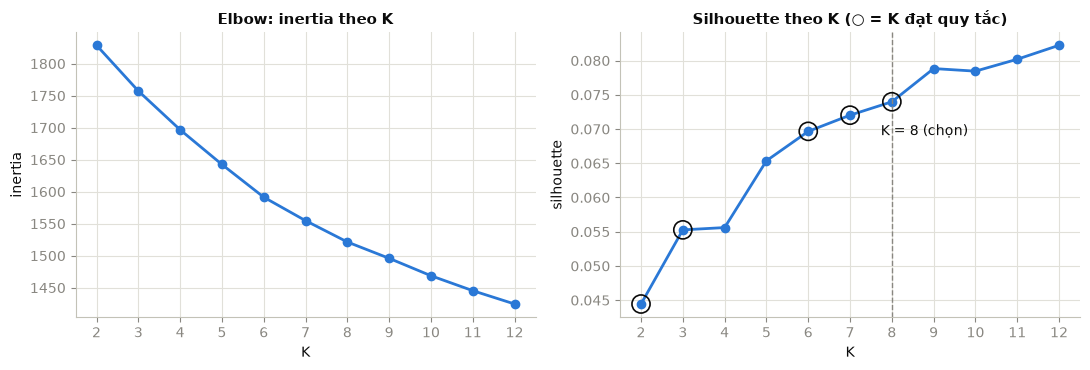

In [19]:
candidates = k_table.loc[k_table["passes_rule"]]
if candidates.empty:  # dữ liệu khác có thể không K nào đạt: lấy K ổn định nhất và báo rõ
    print("Không K nào đạt quy tắc; dùng K có ARI cao nhất.")
    candidates = k_table.loc[[k_table["mean_ari"].idxmax()]]
K_BEST = int(candidates["silhouette"].idxmax())

print("K đạt quy tắc:", candidates.index.tolist())
print("Silhouette của các K đó:", candidates["silhouette"].round(3).to_dict())
print("K được chọn:", K_BEST)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# Elbow
axes[0].plot(k_table.index, k_table["inertia"], marker="o", markersize=6, color=BLUE)
axes[0].set_title("Elbow: inertia theo K")
axes[0].set_xlabel("K")
axes[0].set_ylabel("inertia")

# Silhouette: vòng tròn rỗng đánh dấu K đạt quy tắc
axes[1].plot(k_table.index, k_table["silhouette"], marker="o", markersize=6, color=BLUE)
axes[1].scatter(
    candidates.index, candidates["silhouette"], s=170, facecolors="none", edgecolors=INK, linewidths=1.2, zorder=3
)
axes[1].axvline(K_BEST, color=MUTED, linestyle="--", linewidth=1)
axes[1].annotate(
    f"K = {K_BEST} (chọn)", (K_BEST, candidates.loc[K_BEST, "silhouette"]),
    xytext=(-8, -24), textcoords="offset points", color=INK,
)
axes[1].set_title("Silhouette theo K (○ = K đạt quy tắc)")
axes[1].set_xlabel("K")
axes[1].set_ylabel("silhouette")

for ax in axes:
    ax.set_xticks(list(k_table.index))

plt.tight_layout()
plt.show()

**Cách đọc kết quả**

- **Elbow không có khuỷu rõ:** inertia giảm đều khi tăng K nên không thể chọn K chỉ bằng Elbow. Đây là lý do cần thêm Silhouette và độ ổn định.
- **Silhouette thấp ở mọi K (dưới 0,1):** các cụm chồng lấn nhiều vì nhiều kỹ năng (Git, Docker, SQL…) có mặt ở hầu hết nhóm nghề. Vì vậy các cụm là **xu hướng kỹ năng**, không phải ranh giới cứng giữa các nghề.
- **Silhouette của các K đạt quy tắc chênh nhau rất ít:** K được chọn là ứng viên tốt nhất theo quy tắc, nhưng không vượt trội. Mục 2.3.6 kiểm tra thêm rằng các cụm đặt tên được.
- **Silhouette còn nhích lên ở K = 9–12**, nhưng các K đó không đạt quy tắc (ARI dưới 0,80), nghĩa là cụm kém ổn định khi chạy lại nên không chọn.

## 2.3.5 — Gom cụm và lập hồ sơ cụm

Chạy K-Means với K đã chọn. Cụm được **đánh số lại theo kích thước** (cụm 1 lớn nhất) để dễ đọc; số thứ tự do thuật toán gán là ngẫu nhiên nên không có ý nghĩa.

In [20]:
km_final = KMeans(n_clusters=K_BEST, n_init=10, random_state=RANDOM_STATE).fit(X_norm)

# Đánh số lại: cụm 1 lớn nhất
old_ids_by_size = pd.Series(km_final.labels_).value_counts().index
new_id = {old: rank for rank, old in enumerate(old_ids_by_size, start=1)}

cluster_labels = np.array([new_id[c] for c in km_final.labels_])
df_model["cluster_id"] = cluster_labels

profile = describe_clusters(X_model, cluster_labels, skill_names)

display(
    profile[["n_jobs", "pct", "avg_skills", "distinctive", "common"]]
    .rename(
        columns={
            "n_jobs": "số tin",
            "pct": "% mẫu",
            "avg_skills": "kỹ năng TB/tin",
            "distinctive": "kỹ năng đặc trưng (lift)",
            "common": "kỹ năng phổ biến nhất (% tin trong cụm)",
        }
    )
    .round(1)
)

,số tin,% mẫu,kỹ năng TB/tin,kỹ năng đặc trưng (lift),kỹ năng phổ biến nhất (% tin trong cụm)
cluster,,,,,
1,363,16.4,10.9,"CSS (5.5x), HTML (5.3x), JavaScript (3.7x), React (3.1x), C# (2.8x), TypeScript (2.7x), REST API (2.1x), Git (2.0x)","JavaScript (53%), Git (44%), HTML (44%), CSS (44%), REST API (42%)"
2,339,15.3,6.0,"Power BI (5.0x), ERP (3.0x), SQL (2.7x), Python (1.2x)","SQL (91%), Python (48%), Power BI (32%), ERP (29%), Oracle (21%)"
3,331,14.9,14.9,"Spring Boot (5.1x), Spring (4.8x), Redis (4.7x), Kafka (4.4x), Microservices (4.1x), MongoDB (3.8x), PostgreSQL (3.5x), MySQL (3.2x)","Microservices (69%), Java (68%), PostgreSQL (59%), CI/CD (55%), Docker (55%)"
4,323,14.6,11.1,"Ansible (5.4x), Terraform (5.2x), Bash (3.9x), GitLab (3.6x), Jenkins (3.6x), DevOps (3.4x), Google Cloud (3.3x), Kubernetes (3.3x)","CI/CD (79%), DevOps (72%), AWS (71%), Kubernetes (68%), Docker (57%)"
5,296,13.3,8.3,"Machine Learning (4.4x), LLM (3.9x), Python (2.4x), CI/CD (0.8x)","Python (96%), LLM (54%), Machine Learning (31%), CI/CD (27%), Docker (24%)"
6,211,9.5,5.9,"Cisco (9.0x), Windows Server (7.9x), Firewall (7.7x), VMware (7.2x), Cybersecurity (4.7x), Linux (2.6x)","Firewall (66%), Linux (56%), Cisco (48%), Cybersecurity (43%), VMware (33%)"
7,206,9.3,6.7,"Scrum (6.0x), Jira (4.5x), Agile (4.3x), SQL (1.2x)","Agile (95%), Scrum (86%), Jira (49%), SQL (41%), Postman (18%)"
8,149,6.7,5.9,"C (12.6x), C++ (10.5x), Linux (2.7x), Python (1.5x)","C++ (99%), C (79%), Python (60%), Linux (58%), Git (24%)"


**Hai cột kỹ năng, hai ý nghĩa**

- *Kỹ năng đặc trưng (lift):* cụm này nhắc nhiều hơn mức bình thường. Đây là cột dùng để đặt tên.
- *Kỹ năng phổ biến nhất:* chiếm tỷ lệ cao trong cụm, nhưng có thể cũng phổ biến ở cụm khác (ví dụ Python, SQL). Cột này cho biết cụm "thường có gì", không cho biết cụm "khác gì".

### Bối cảnh của từng cụm: nhóm nghề, cấp bậc, lương

Các cột này **không** tham gia gom cụm. Chúng chỉ giúp kiểm tra xem cụm có hợp lý không (ví dụ cụm DevOps nên có nhiều tin `devops_cloud`).

In [21]:
def top_share(series, n=2):
    """Chuỗi "nhãn tỷ lệ%" của n nhãn phổ biến nhất."""
    return ", ".join(f"{label} {share * 100:.0f}%" for label, share in series.value_counts(normalize=True).head(n).items())


level_order = ["Intern", "Fresher", "Junior", "Middle", "Senior", "Lead", "Multi-level", "Unknown"]

roles = df_model.groupby("cluster_id")["title_role"].apply(top_share).rename("nhóm nghề phổ biến")

seniority_mix = (
    pd.crosstab(df_model["cluster_id"], df_model["seniority_clean"], normalize="index")
    .reindex(columns=level_order, fill_value=0)
    * 100
).round(0)

salary_view = (
    df_model.loc[df_model["salary_eda_eligible"]]
    .groupby("cluster_id")["Luong_TB"]
    .agg(luong_trung_vi_trieu=lambda s: s.median() / 1e6, n_co_luong="size")
    .round(1)
)

context = pd.concat([roles, seniority_mix.add_prefix("% "), salary_view], axis=1)
display(context)

,nhóm nghề phổ biến,% Intern,% Fresher,% Junior,% Middle,% Senior,% Lead,% Multi-level,% Unknown,luong_trung_vi_trieu,n_co_luong
cluster_id,,,,,,,,,,,
1,"software 33%, fullstack 21%",5.0,4.0,28.0,15.0,26.0,9.0,6.0,8.0,21.0,89
2,"data_ai 42%, it_general 18%",1.0,2.0,33.0,20.0,23.0,13.0,2.0,6.0,25.0,74
3,"software 35%, backend 27%",0.0,1.0,15.0,21.0,32.0,18.0,7.0,6.0,35.0,63
4,"devops_cloud 53%, data_ai 13%",0.0,2.0,19.0,17.0,35.0,14.0,5.0,8.0,32.5,43
5,"data_ai 37%, it_general 17%",5.0,1.0,18.0,22.0,27.0,9.0,6.0,12.0,28.8,68
6,"system_network 33%, it_general 21%",2.0,3.0,36.0,22.0,18.0,13.0,2.0,5.0,18.8,57
7,"generic 22%, qa_test 17%",1.0,2.0,28.0,23.0,21.0,18.0,2.0,3.0,23.0,57
8,"software 42%, embedded 21%",5.0,7.0,35.0,9.0,18.0,7.0,3.0,15.0,23.8,25


**Lưu ý khi đọc bảng lương:** `n_co_luong` chỉ vài chục tin mỗi cụm, và phần lớn đến từ TopCV với kỳ trả lương là giả định (xem 2.2). Chỉ dùng để tham khảo, không so sánh lương giữa các cụm như một kết luận.

### Tin mẫu của mỗi cụm

Hai tin gần tâm cụm nhất, kèm đường dẫn để mở xem tin gốc.

In [22]:
sample_rows = []
for c in sorted(profile.index):
    members = np.where(cluster_labels == c)[0]
    centroid = X_norm[members].mean(axis=0)
    distance = np.linalg.norm(X_norm[members] - centroid, axis=1)

    for i in members[np.argsort(distance)[:2]]:
        row = df_model.iloc[i]
        sample_rows.append(
            {"cụm": c, "title": row["title"], "company": row["company"], "source": row["source"], "URL_Goc": row["URL_Goc"]}
        )

display(pd.DataFrame(sample_rows).set_index("cụm"))

,title,company,source,URL_Goc
cụm,,,,
1,Full Stack Developer (.Net),Công ty TNHH Tổng công ty Công nghệ & Giải pháp CMC,topcv,https://www.topcv.vn/viec-lam/full-stack-developer-net/2338718.html
1,"Senior Full-Stack Software Developer (.NET, React/Angular/Vue.js)",Công Ty TNHH Mi-Jack Manufacturing Global Viet Nam,vietnamworks,https://www.vietnamworks.com/senior-full-stack-software-developer-net-react-angular-vue-js-1794369395290272610-2129831-jv
2,AI Engineer,Nefab Vietnam,vietnamworks,https://www.vietnamworks.com/ai-engineer--2124710-jv
2,RPA Developer,Navigos Search's Client,vietnamworks,https://www.vietnamworks.com/rpa-developer-1794835856431421053-2131926-jv
3,Lập Trình Viên Fullstack - Đi Làm Ngay - Thu Nhập Từ 20 -34 Triệu / Tháng,Công ty Cổ phần SIMBATECH,topcv,https://www.topcv.vn/viec-lam/lap-trinh-vien-fullstack-di-lam-ngay-thu-nhap-tu-20-34-trieu-thang/1713501.html
3,Senior/Expert Java Developer (HN/HCMC),One Mount,linkedin,https://www.linkedin.com/jobs/view/4479970560
4,Kỹ Sư DevOps,TỔNG CÔNG TY VIỄN THÔNG VIETTEL-CHI NHÁNH TẬP ĐOÀN CÔNG NGHIỆP - VIỄN THÔNG QUÂN ĐỘI,topcv,https://www.topcv.vn/viec-lam/ky-su-devops/2278678.html
4,DevOps Engineer (Junior/Middle),Amaris Consulting | Part of Mantu,linkedin,https://www.linkedin.com/jobs/view/4484332323
5,"AI Engineer (RPA, LLM, ML, API)",Công ty Cổ phần Vàng bạc đá quý Bảo Tín Mạnh Hải,itviec,https://itviec.com/it-jobs/ai-engineer-rpa-llm-ml-api-cong-ty-co-phan-vang-bac-da-quy-bao-tin-manh-hai-1734


## 2.3.6 — Đặt tên cụm

Tên cụm dựa vào **kỹ năng đặc trưng (lift)**, không dựa vào cảm tính. Mỗi tên có một "chữ ký" là các kỹ năng tiêu biểu. Một cụm nhận tên có nhiều kỹ năng trùng chữ ký nhất, và cần trùng ít nhất 2 kỹ năng; nếu không, cụm được ghi "chưa đặt tên" để người đọc tự xem.

Cách làm này giúp tên **không bị lệch** khi chạy lại ở máy khác (số thứ tự cụm có thể đổi, nhưng kỹ năng đặc trưng thì không).

In [23]:
CLUSTER_SIGNATURES = {
    "Data Science / ML / LLM": {"Machine Learning", "LLM", "Python"},
    "Backend Java (Spring, Microservices)": {"Spring Boot", "Spring", "Redis", "Kafka", "Microservices", "MongoDB"},
    "Dữ liệu doanh nghiệp (SQL, BI, ERP)": {"Power BI", "ERP", "Oracle", "Tableau", "SQL"},
    "Hệ thống, mạng và bảo mật": {"Cisco", "Firewall", "VMware", "Windows Server", "Cybersecurity"},
    "DevOps / Cloud (CI/CD, Terraform, K8s)": {"Ansible", "Terraform", "Jenkins", "GitLab", "DevOps", "Kubernetes", "Bash"},
    "Quy trình Agile / Scrum": {"Scrum", "Agile", "Jira"},
    "C / C++ và Linux": {"C", "C++", "Linux"},
    "Frontend và Web (HTML, JS, React)": {"HTML", "CSS", "JavaScript", "React", "TypeScript", "Angular"},
}

cluster_names, overlaps = name_clusters(profile["top_lift"], CLUSTER_SIGNATURES)
df_model["cluster_name"] = df_model["cluster_id"].map(cluster_names)

naming_check = pd.DataFrame(
    {"tên cụm": pd.Series(cluster_names), "số kỹ năng trùng chữ ký": pd.Series(overlaps)}
).rename_axis("cụm")
display(naming_check)

assert not any("chưa đặt tên" in name for name in cluster_names.values()), "Có cụm chưa đặt tên: xem lại chữ ký"
assert len(set(cluster_names.values())) == len(cluster_names), "Hai cụm trùng tên: xem lại chữ ký"

,tên cụm,số kỹ năng trùng chữ ký
cụm,,
1,"Frontend và Web (HTML, JS, React)",5
2,"Dữ liệu doanh nghiệp (SQL, BI, ERP)",3
3,"Backend Java (Spring, Microservices)",6
4,"DevOps / Cloud (CI/CD, Terraform, K8s)",7
5,Data Science / ML / LLM,3
6,"Hệ thống, mạng và bảo mật",5
7,Quy trình Agile / Scrum,3
8,C / C++ và Linux,3


### Bảng chân dung cụm

,tên cụm,số tin,% mẫu,kỹ năng TB/tin,kỹ năng đặc trưng (lift),nhóm nghề phổ biến,lương trung vị (triệu),n có lương
cụm,,,,,,,,
1,"Frontend và Web (HTML, JS, React)",363,16.4,10.9,"CSS (5.5x), HTML (5.3x), JavaScript (3.7x), React (3.1x), C# (2.8x), TypeScript (2.7x), REST API (2.1x), Git (2.0x)","software 33%, fullstack 21%",21.0,89
2,"Dữ liệu doanh nghiệp (SQL, BI, ERP)",339,15.3,6.0,"Power BI (5.0x), ERP (3.0x), SQL (2.7x), Python (1.2x)","data_ai 42%, it_general 18%",25.0,74
3,"Backend Java (Spring, Microservices)",331,14.9,14.9,"Spring Boot (5.1x), Spring (4.8x), Redis (4.7x), Kafka (4.4x), Microservices (4.1x), MongoDB (3.8x), PostgreSQL (3.5x), MySQL (3.2x)","software 35%, backend 27%",35.0,63
4,"DevOps / Cloud (CI/CD, Terraform, K8s)",323,14.6,11.1,"Ansible (5.4x), Terraform (5.2x), Bash (3.9x), GitLab (3.6x), Jenkins (3.6x), DevOps (3.4x), Google Cloud (3.3x), Kubernetes (3.3x)","devops_cloud 53%, data_ai 13%",32.5,43
5,Data Science / ML / LLM,296,13.3,8.3,"Machine Learning (4.4x), LLM (3.9x), Python (2.4x), CI/CD (0.8x)","data_ai 37%, it_general 17%",28.8,68
6,"Hệ thống, mạng và bảo mật",211,9.5,5.9,"Cisco (9.0x), Windows Server (7.9x), Firewall (7.7x), VMware (7.2x), Cybersecurity (4.7x), Linux (2.6x)","system_network 33%, it_general 21%",18.8,57
7,Quy trình Agile / Scrum,206,9.3,6.7,"Scrum (6.0x), Jira (4.5x), Agile (4.3x), SQL (1.2x)","generic 22%, qa_test 17%",23.0,57
8,C / C++ và Linux,149,6.7,5.9,"C (12.6x), C++ (10.5x), Linux (2.7x), Python (1.5x)","software 42%, embedded 21%",23.8,25


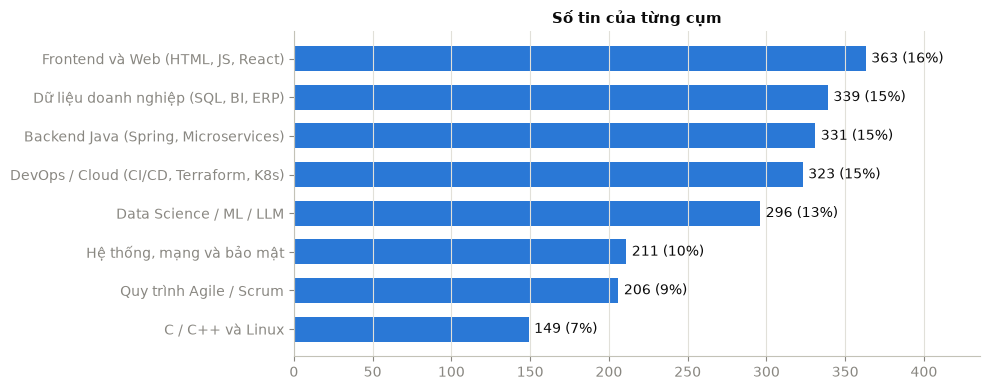

In [24]:
portrait = pd.concat(
    [
        pd.Series(cluster_names, name="tên cụm"),
        profile[["n_jobs", "pct", "avg_skills", "distinctive"]],
        roles,
        salary_view,
    ],
    axis=1,
).rename(
    columns={
        "n_jobs": "số tin",
        "pct": "% mẫu",
        "avg_skills": "kỹ năng TB/tin",
        "distinctive": "kỹ năng đặc trưng (lift)",
        "luong_trung_vi_trieu": "lương trung vị (triệu)",
        "n_co_luong": "n có lương",
    }
).rename_axis("cụm")

display(portrait.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
sizes = portrait.sort_values("số tin")
bars = ax.barh(sizes["tên cụm"], sizes["số tin"], color=BLUE, height=0.65)
ax.bar_label(bars, labels=[f"{n:,} ({p:.0f}%)" for n, p in zip(sizes["số tin"], sizes["% mẫu"])], padding=4, color=INK)
ax.set_xlim(0, sizes["số tin"].max() * 1.2)
ax.set_title("Số tin của từng cụm")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 2.3.7 — Kiểm tra độ tin cậy của cụm

Ba câu hỏi:

1. **Cụm có ổn định không?** Chạy lại với hạt giống khác có ra cụm giống không (ARI).
2. **Cụm nào kém chặt?** Silhouette riêng từng cụm; âm nghĩa là nhiều tin gần cụm khác hơn cụm của mình.
3. **Cụm có phản ánh nguồn dữ liệu không?** Nếu một cụm gần như chỉ đến từ một nguồn thì có thể là cách nguồn đó viết JD, không phải loại việc.

In [25]:
print(f"ARI trung bình giữa các lần chạy (K = {K_BEST}): {k_table.loc[K_BEST, 'mean_ari']:.2f}")

sample_silhouette = silhouette_samples(X_norm, cluster_labels)
silhouette_by_cluster = (
    pd.Series(sample_silhouette).groupby(cluster_labels).mean().rename("silhouette TB").round(3)
)

print(f"Silhouette toàn mẫu: {sample_silhouette.mean():.3f}")
display(pd.concat([pd.Series(cluster_names, name="tên cụm"), silhouette_by_cluster], axis=1).rename_axis("cụm"))

ARI trung bình giữa các lần chạy (K = 8): 0.86
Silhouette toàn mẫu: 0.074


,tên cụm,silhouette TB
cụm,,
1,"Frontend và Web (HTML, JS, React)",0.016
2,"Dữ liệu doanh nghiệp (SQL, BI, ERP)",0.057
3,"Backend Java (Spring, Microservices)",0.052
4,"DevOps / Cloud (CI/CD, Terraform, K8s)",0.101
5,Data Science / ML / LLM,0.030
6,"Hệ thống, mạng và bảo mật",0.103
7,Quy trình Agile / Scrum,0.142
8,C / C++ và Linux,0.196


**Kết quả lần chạy này:** không cụm nào có Silhouette âm. Cụm *C / C++ và Linux* và *Quy trình Agile / Scrum* tách rõ nhất vì có bộ kỹ năng riêng. Cụm *Frontend và Web* kém chặt nhất vì JavaScript, React, C#, Git cũng xuất hiện ở backend, fullstack và nhiều nhóm khác. Cụm *Data Science / ML / LLM* cũng lẫn vì Python có mặt ở hầu hết nhóm.

In [26]:
source_mix = (pd.crosstab(df_model["cluster_id"], df_model["source"], normalize="index") * 100).round(0)
source_mix.loc["Toàn mẫu"] = (df_model["source"].value_counts(normalize=True) * 100).round(0)

display(source_mix.rename_axis("cụm (% tin theo nguồn)"))

source,itviec,linkedin,topcv,topdev,vietnamworks
cụm (% tin theo nguồn),,,,,
1,18.0,32.0,36.0,2.0,12.0
2,17.0,15.0,35.0,4.0,29.0
3,25.0,30.0,31.0,2.0,12.0
4,26.0,37.0,27.0,2.0,8.0
5,25.0,29.0,27.0,2.0,17.0
6,11.0,3.0,57.0,1.0,28.0
7,23.0,10.0,50.0,2.0,14.0
8,14.0,48.0,23.0,1.0,13.0
Toàn mẫu,21.0,26.0,35.0,2.0,16.0


**Cách đọc:** so từng dòng với dòng "Toàn mẫu". Cụm lệch nhiều so với toàn mẫu thì cần thận trọng khi diễn giải, vì phần chênh có thể đến từ cách một nguồn gắn thẻ kỹ năng.

**Kết quả lần chạy này:** cụm *Hệ thống, mạng và bảo mật* (TopCV 57%, LinkedIn 3%) và cụm *C / C++ và Linux* (LinkedIn 48%) lệch rõ nhất so với toàn mẫu (TopCV 35%, LinkedIn 26%). Các cụm còn lại gần với cơ cấu chung. Các bước sau (2.4, 2.5) nên kiểm lại kết quả theo từng nguồn.

## 2.3.8 — Hình 2D (PCA)

PCA ép 143 chiều xuống 2 chiều để **nhìn**. Nó chỉ phục vụ minh họa, **không** dùng để chọn K hay gom cụm. Mỗi ô nhấn một cụm (màu xanh) trên nền toàn bộ tin (xám), nên không cần phân biệt nhiều màu.

Phần biến thiên giữ lại bởi 2 trục: 12.8 %


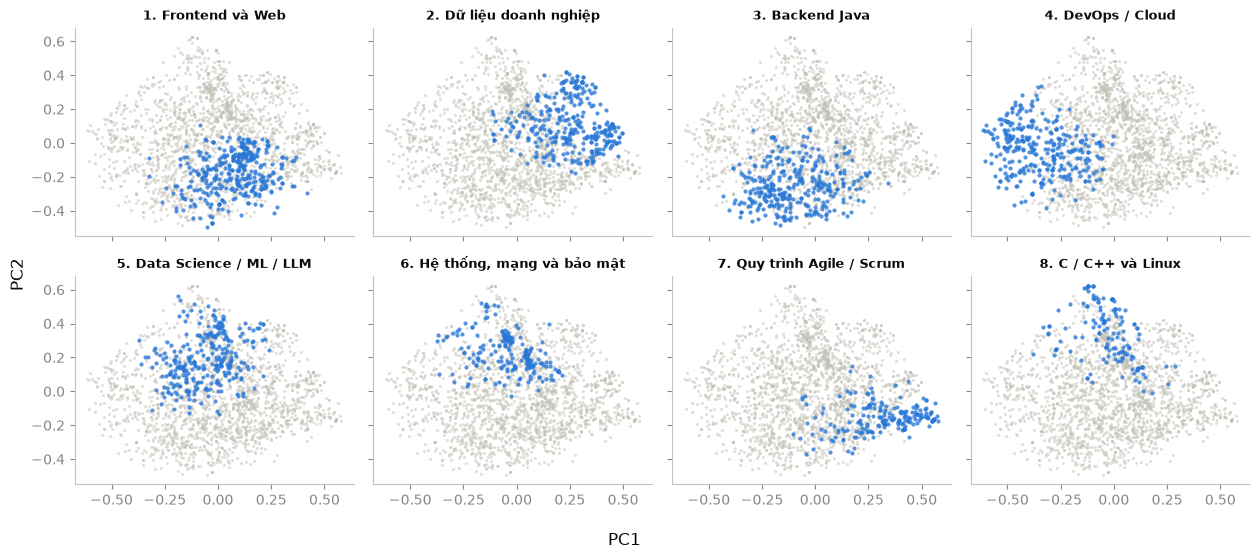

In [27]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
points = pca.fit_transform(X_norm)

print("Phần biến thiên giữ lại bởi 2 trục:", (pca.explained_variance_ratio_.sum() * 100).round(1), "%")

n_cols = 4
n_rows = int(np.ceil(K_BEST / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.8 * n_rows), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, c in zip(axes, sorted(profile.index)):
    mask = cluster_labels == c
    ax.scatter(points[~mask, 0], points[~mask, 1], s=5, color=GRAY, alpha=0.5, linewidths=0)
    ax.scatter(points[mask, 0], points[mask, 1], s=9, color=BLUE, alpha=0.8, linewidths=0)
    ax.set_title(f"{c}. {cluster_names[c].split(' (')[0]}", fontsize=9)
    ax.grid(False)

for ax in axes[K_BEST:]:
    ax.axis("off")

fig.supxlabel("PC1")
fig.supylabel("PC2")
plt.tight_layout()
plt.show()

Mỗi cụm chiếm một vùng riêng trên mặt phẳng (ví dụ DevOps / Cloud ở bên trái, Agile / Scrum ở phía dưới bên phải), nhưng vùng của các cụm **chồng lấn nhiều**. Điều này khớp với Silhouette thấp ở 2.3.4: cụm có hướng riêng, không có ranh giới sạch. Hai trục chỉ giữ khoảng 13% biến thiên của dữ liệu, nên hình chỉ mang tính minh họa.

## 2.3.9 — Tổng kết mẫu số và lưu kết quả

Mọi tin IT có JD đều được ghi lại với một trạng thái, để bước sau biết tin nào có cụm và tin nào không.

| `cluster_status` | Ý nghĩa |
| ---------------- | ------- |
| `clustered` | Đã được gom cụm |
| `no_skills_extracted` | Có JD nhưng không trích được kỹ năng (nhóm báo riêng, xem 2.3.2) |
| `too_few_skills` | Còn dưới 3 kỹ năng sau khi bỏ kỹ năng hiếm |

In [28]:
# Tin không có trong df_model nhận cluster_id trống
assignments = df_skills[["job_uid"]].merge(
    df_model[["job_uid", "cluster_id", "cluster_name"]], on="job_uid", how="left"
)
assignments["cluster_id"] = assignments["cluster_id"].astype("Int64")

assignments["cluster_status"] = np.select(
    [assignments["cluster_id"].notna().to_numpy(), df_skills["n_skills"].eq(0).to_numpy()],
    ["clustered", "no_skills_extracted"],
    default="too_few_skills",
)

# Đối chiếu mẫu số: mọi tin có JD được tính đúng một lần
assert assignments["job_uid"].is_unique
assert len(assignments) == len(df_skills)
assert assignments["cluster_status"].eq("clustered").sum() == len(df_model)

summary = (
    assignments.assign(nhom=assignments["cluster_name"].fillna(assignments["cluster_status"]))
    .groupby("nhom").size().sort_values(ascending=False).rename("số tin").to_frame()
)
summary.loc["Tổng"] = summary["số tin"].sum()
display(summary)

,số tin
nhom,
too_few_skills,450
"Frontend và Web (HTML, JS, React)",363
"Dữ liệu doanh nghiệp (SQL, BI, ERP)",339
"Backend Java (Spring, Microservices)",331
"DevOps / Cloud (CI/CD, Terraform, K8s)",323
Data Science / ML / LLM,296
"Hệ thống, mạng và bảo mật",211
Quy trình Agile / Scrum,206
no_skills_extracted,175


In [29]:
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
assignments.to_csv(OUTPUT_PATH, index=False, encoding="utf-8-sig")
print(f"Đã lưu {len(assignments):,} tin vào {OUTPUT_PATH}")

# Đọc lại để kiểm tra
loaded = pd.read_csv(OUTPUT_PATH)
assert loaded["job_uid"].tolist() == assignments["job_uid"].tolist()
assert loaded["cluster_id"].isna().sum() == (assignments["cluster_status"] != "clustered").sum()
print("Đọc lại thành công:", loaded.shape)

Đã lưu 2,843 tin vào data\cluster_assignments.csv
Đọc lại thành công: (2843, 4)


## Kết luận và giới hạn

**Kết quả chính:** tập tin IT có JD chia được thành các nhóm kỹ năng đặt tên được (bảng chân dung ở 2.3.6). Kết quả ổn định khi chạy lại với hạt giống khác.

**Giới hạn cần nói rõ khi trình bày**

- Silhouette thấp (dưới 0,1): đây là các **xu hướng kỹ năng chồng lấn**, không phải nhóm nghề tách biệt.
- Cụm dựa trên kỹ năng **được trích xuất** từ từ điển ở 2.1. Kỹ năng bị bỏ sót sẽ không ảnh hưởng tới cụm, và ngưỡng 3 kỹ năng/tin đã loại bớt tin ghi ít.
- Nhóm nghề, cấp bậc, lương chỉ dùng để **mô tả** cụm, không tham gia gom cụm. Lương chủ yếu từ TopCV và có giả định kỳ trả.
- Chọn K là một lựa chọn có quy tắc nhưng không có đáp án duy nhất; xem bảng 2.3.4 nếu muốn thử K khác.

**Nối sang các bước sau**

- 2.4: chạy luật kết hợp trong từng cụm để thấy bộ kỹ năng đi cùng nhau trong từng nhóm.
- 2.5: có thể dùng `cluster_name` làm thông tin mô tả; nếu dùng làm đặc trưng dự đoán cấp bậc hoặc lương thì phải kiểm tra rò rỉ.